# Forecasting Store-Level Liquor Demand in Iowa
### Keaton Ludwig

### Description

This Jupyter Notebook contains the complete data science workflow for the DSC-680 Applied Data Science project on predictive demand analytics for liquor distribution. Using approximately eight months of Iowa liquor sales data, the notebook documents data cleaning, exploratory analysis, feature engineering, demand aggregation, predictive modeling, model validation, and visualization. The primary objective is to determine whether historical product- and store-level purchasing patterns can be used to predict near-term future demand and support inventory-planning decisions for beverage distributors. The notebook also includes reproducible code, model comparisons, evaluation metrics, and visualizations used to support the Milestone 2 white paper.

## 1. Setup
All tunable choices live in this cell so they are visible in one place and can be cited in the paper. The week calendar uses **Monday-start weeks**; 1 January 2026 is a Thursday and 31 August 2026 is a Monday, so the analysis uses the 34 complete weeks from 5 January to 30 August 2026.

In [1]:
import json
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Paths ----
DATA_DIR = Path(".")                       # folder holding the four CSV parts
FILE_PATTERN = "iowa_liquor_sales_2026_1263_rows_part_*.csv"
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# ---- Analysis design ----
SEED = 27
PORTAL_ROW_COUNT = 1_604_208               # row count published on the Iowa Data Hub (dataset 1263)
FIRST_WEEK_START = pd.Timestamp("2026-01-05")   # Monday of week 1
LAST_WEEK_END = pd.Timestamp("2026-08-30")      # Sunday of week 34
HORIZON = 4                                # predict total bottles over the next 4 weeks
ACTIVITY_WINDOW = 8                        # eligibility at each origin: purchases in >= 3 ...
MIN_ACTIVE_WEEKS = 3                       # ... of the 8 weeks up to and including the origin
STATIC_END_WEEK = 26                       # static attributes / segment tiers use weeks 1-26 only
FIRST_ORIGIN = 8                           # first forecast origin (needs 8 weeks of history)
TRAIN_LAST_ORIGIN = 22                     # last training origin: its target window ends in week 26
TEST_ORIGINS = list(range(26, 31))         # test origins 26-30: target windows cover weeks 27-34
CV_FOLDS = [                               # rolling-origin folds inside the training period
    {"train_max": 10, "val": [14, 15, 16]},
    {"train_max": 13, "val": [17, 18, 19]},
    {"train_max": 16, "val": [20, 21, 22]},
]
# US federal holidays that fall inside the modeled calendar (known in advance, so not leakage)
HOLIDAYS_2026 = pd.to_datetime([
    "2026-01-19", "2026-02-16", "2026-05-25", "2026-06-19", "2026-07-03", "2026-09-07",
])

RESULTS = {}                               # every headline number lands here -> results_summary.json

# ---- Figure style (print-friendly, colorblind-validated palette) ----
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, BLUE_DARK, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#184f95", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY = "#9a9994"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
print("Setup complete.")

Setup complete.


## 2. Load the data
The Iowa Data Hub export arrived as four CSV parts. Identifier columns (store, item, vendor, category, ZIP, county FIPS) are read as text so leading zeros are preserved and they are never treated as numbers.

In [2]:
files = sorted(DATA_DIR.glob(FILE_PATTERN))
assert len(files) > 0, f"No files matching {FILE_PATTERN} in {DATA_DIR.resolve()}"

ID_COLS = ["invoice_id", "store_no", "store_zip_code", "county_fips_code",
           "category_code", "vendor_number", "item_no"]
parts = []
for f in files:
    part = pd.read_csv(f, dtype={c: str for c in ID_COLS})
    print(f"{f.name}: {len(part):,} rows")
    parts.append(part)
raw = pd.concat(parts, ignore_index=True)
del parts
print(f"\nCombined: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
RESULTS["raw_rows"] = int(raw.shape[0])
RESULTS["n_columns"] = int(raw.shape[1])

iowa_liquor_sales_2026_1263_rows_part_0001.csv: 472,859 rows
iowa_liquor_sales_2026_1263_rows_part_0002.csv: 567,088 rows
iowa_liquor_sales_2026_1263_rows_part_0003.csv: 564,261 rows
iowa_liquor_sales_2026_1263_rows_part_0004.csv: 364,146 rows

Combined: 1,968,354 rows x 23 columns


## 3. Initial inspection
Column types, a sample of rows, and cardinality of the key fields. The goal is to confirm the schema matches the official release before anything is changed.

In [3]:
print(raw.dtypes.to_string())
display(raw.head(3))

card = raw.nunique().rename("unique_values").to_frame()
card["dtype"] = raw.dtypes.astype(str)
display(card)

invoice_id              object
ordered_on              object
store_no                object
store_name              object
store_address           object
store_city              object
store_zip_code          object
county_fips_code        object
county_name             object
category_code           object
category_name           object
vendor_number           object
vendor_name             object
item_no                 object
im_desc                 object
pack                     int64
bottle_volume_ml         int64
state_bottle_cost      float64
state_bottle_retail    float64
sales_bottles            int64
sales_dollars          float64
sales_liters           float64
sales_gallons          float64


,invoice_id,ordered_on,store_no,store_name,store_address,store_city,store_zip_code,county_fips_code,county_name,category_code,...,item_no,im_desc,pack,bottle_volume_ml,state_bottle_cost,state_bottle_retail,sales_bottles,sales_dollars,sales_liters,sales_gallons
0,INV-903316,2026-01-01,5444,MARSHALL BEER WINE SPIRITS,11 N 3RD AVE,MARSHALLTOWN,50158,19127,MARSHALL,1022200,...,88296,PATRON SILVER,12,750,24.99,37.49,60,2249.40,45.0,11.887740
1,INV-903316,2026-01-01,5444,MARSHALL BEER WINE SPIRITS,11 N 3RD AVE,MARSHALLTOWN,50158,19127,MARSHALL,1082200,...,69947,RUMPLE MINZE PEPPERMINT SCHNAPPS LIQUEUR,12,1000,16.99,25.49,36,917.64,36.0,9.510192
2,INV-903479,2026-01-02,4417,MAVERIK #5066 / ADAIR,109 S 5TH ST,ADAIR,50002,19001,ADAIR,1022200,...,87484,DON JULIO BLANCO,12,375,14.00,22.00,3,67.00,1.0,0.000000


,unique_values,dtype
invoice_id,82673,object
ordered_on,192,object
store_no,2203,object
store_name,2186,object
store_address,2178,object
store_city,473,object
store_zip_code,508,object
county_fips_code,99,object
county_name,99,object
category_code,44,object


## 4. Type correction and dates
`ordered_on` becomes a true date. Numeric fields are checked for values that fail to parse.

In [4]:
raw["ordered_on"] = pd.to_datetime(raw["ordered_on"], format="%Y-%m-%d", errors="coerce")
num_cols = ["pack", "bottle_volume_ml", "state_bottle_cost", "state_bottle_retail",
            "sales_bottles", "sales_dollars", "sales_liters", "sales_gallons"]
for c in num_cols:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

print("Unparseable dates:", int(raw["ordered_on"].isna().sum()))
print("Unparseable numerics:", {c: int(raw[c].isna().sum()) for c in num_cols})
print("Date range:", raw["ordered_on"].min().date(), "to", raw["ordered_on"].max().date())
print("Distinct order dates:", raw["ordered_on"].nunique())
RESULTS["date_min"] = str(raw["ordered_on"].min().date())
RESULTS["date_max"] = str(raw["ordered_on"].max().date())
RESULTS["distinct_order_dates"] = int(raw["ordered_on"].nunique())

Unparseable dates: 0
Unparseable numerics: {'pack': 0, 'bottle_volume_ml': 0, 'state_bottle_cost': 0, 'state_bottle_retail': 0, 'sales_bottles': 0, 'sales_dollars': 0, 'sales_liters': 0, 'sales_gallons': 0}
Date range: 2026-01-01 to 2026-08-31
Distinct order dates: 192


## 5. Missing values

In [5]:
missing = raw.isna().sum().rename("missing").to_frame()
missing["pct"] = (missing["missing"] / len(raw) * 100).round(3)
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
display(missing)
missing.to_csv(OUT_DIR / "missing_values_raw.csv")

,missing,pct
store_address,4129,0.210
store_city,4129,0.210
store_zip_code,4129,0.210
county_fips_code,4129,0.210
county_name,4129,0.210
category_code,32,0.002
category_name,32,0.002


## 6. Duplicate analysis
Milestone 1 found that the delivered export contains exact duplicate rows concentrated in July and August. This cell re-verifies that finding and compares the de-duplicated count with the row count the Iowa Data Hub publishes, which acts as an external check that de-duplication is correct.

In [6]:
dup_mask = raw.duplicated(keep="first")
by_month = (raw.assign(month=raw["ordered_on"].dt.month, is_dup=dup_mask)
               .groupby("month")
               .agg(rows=("is_dup", "size"), exact_duplicates=("is_dup", "sum")))
by_month["dup_pct"] = (by_month["exact_duplicates"] / by_month["rows"] * 100).round(1)
display(by_month)
by_month.to_csv(OUT_DIR / "duplicates_by_month.csv")

n_dup = int(dup_mask.sum())
n_after = len(raw) - n_dup
print(f"Exact duplicate rows: {n_dup:,}")
print(f"Rows after de-duplication: {n_after:,}  |  portal count: {PORTAL_ROW_COUNT:,}  |  difference: {n_after - PORTAL_ROW_COUNT:+,}")
RESULTS.update(exact_duplicates=n_dup, rows_after_dedup=n_after, portal_row_count=PORTAL_ROW_COUNT,
               dedup_vs_portal_diff=int(n_after - PORTAL_ROW_COUNT))

# Keep the raw daily bottle totals for Figure 1 (before vs after de-duplication)
raw_daily_bottles = raw.groupby("ordered_on")["sales_bottles"].sum()

,rows,exact_duplicates,dup_pct
month,,,
1,182995,0,0.0
2,174168,0,0.0
3,201947,1,0.0
4,199762,0,0.0
5,206075,0,0.0
6,219923,12,0.0
7,380372,162590,42.7
8,403112,201557,50.0


Exact duplicate rows: 364,160
Rows after de-duplication: 1,604,194  |  portal count: 1,604,208  |  difference: -14


## 7. Data cleaning
Each rule below is logged so the paper and appendix can report exactly what changed.

1. **Remove exact duplicates** (export artifact).
2. **Fill missing store geography** from the same store's other rows; anything still missing becomes `UNKNOWN`.
3. **Fill missing category** from the same item's other rows; otherwise `UNKNOWN`.
4. **Keep negative bottle lines** (returns/adjustments). They are netted into weekly totals and weekly net totals below zero are floored at zero, because the target is purchases, not returns.
5. **Keep zero-price lines and repeated invoice-item lines** — they are legitimate records and do not affect bottle counts.

In [7]:
df = raw.loc[~dup_mask].copy()
log = [("Rows as delivered", len(raw)), ("Exact duplicate rows removed", n_dup), ("Rows after de-duplication", len(df))]

geo_cols = ["store_address", "store_city", "store_zip_code", "county_fips_code", "county_name"]
geo_missing_before = int(df["store_city"].isna().sum())
geo_lookup = (df.dropna(subset=["store_city"]).groupby("store_no")[geo_cols]
                .agg(lambda s: s.mode().iat[0]))
for c in geo_cols:
    df[c] = df[c].fillna(df["store_no"].map(geo_lookup[c])).fillna("UNKNOWN")
geo_still_unknown = int((df["store_city"] == "UNKNOWN").sum())
log += [("Rows missing store geography", geo_missing_before),
        ("  ...filled from same store's other rows", geo_missing_before - geo_still_unknown),
        ("  ...left as UNKNOWN", geo_still_unknown)]

cat_missing_before = int(df["category_name"].isna().sum())
cat_lookup = (df.dropna(subset=["category_name"]).groupby("item_no")[["category_code", "category_name"]]
                .agg(lambda s: s.mode().iat[0]))
for c in ["category_code", "category_name"]:
    df[c] = df[c].fillna(df["item_no"].map(cat_lookup[c])).fillna("UNKNOWN")
cat_still_unknown = int((df["category_name"] == "UNKNOWN").sum())
log += [("Rows missing category", cat_missing_before),
        ("  ...filled from same item's other rows", cat_missing_before - cat_still_unknown),
        ("  ...left as UNKNOWN", cat_still_unknown)]

neg = df["sales_bottles"] < 0
log += [("Negative-bottle lines (returns/adjustments, kept and netted)", int(neg.sum())),
        ("  ...bottles on those lines", int(df.loc[neg, "sales_bottles"].sum())),
        ("Zero-cost lines (kept)", int((df["state_bottle_cost"] <= 0).sum())),
        ("Repeated invoice-item lines (kept)", int(df.duplicated(["invoice_id", "item_no"]).sum()))]

cleaning_log = pd.DataFrame(log, columns=["step", "count"])
display(cleaning_log)
cleaning_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
RESULTS["cleaning_log"] = {s.strip(): int(c) for s, c in log}
RESULTS["clean_rows"] = int(len(df))
del raw          # free memory; the raw daily totals needed for Figure 1 were saved in Section 6

,step,count
0,Rows as delivered,1968354
1,Exact duplicate rows removed,364160
2,Rows after de-duplication,1604194
3,Rows missing store geography,2365
4,...filled from same store's other rows,1622
5,...left as UNKNOWN,743
6,Rows missing category,26
7,...filled from same item's other rows,0
8,...left as UNKNOWN,26
9,"Negative-bottle lines (returns/adjustments, ke...",1247


## 8. Descriptive statistics
Scale of the cleaned data and how concentrated purchasing is across products and stores.

In [8]:
desc = df[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T.round(2)
display(desc)
desc.to_csv(OUT_DIR / "numeric_describe.csv")

scale = {
    "invoices": df["invoice_id"].nunique(), "stores": df["store_no"].nunique(),
    "products": df["item_no"].nunique(), "categories": df["category_name"].nunique(),
    "vendors": df["vendor_name"].nunique(), "counties": df["county_name"].nunique(),
    "cities": df["store_city"].nunique(), "total_bottles": int(df["sales_bottles"].sum()),
}
item_vol = df.groupby("item_no")["sales_bottles"].sum().sort_values(ascending=False)
store_vol = df.groupby("store_no")["sales_bottles"].sum().sort_values(ascending=False)
scale["top1pct_products_bottle_share"] = round(float(item_vol.head(int(np.ceil(len(item_vol) * 0.01))).sum() / item_vol.sum()), 4)
scale["top10pct_stores_bottle_share"] = round(float(store_vol.head(int(np.ceil(len(store_vol) * 0.10))).sum() / store_vol.sum()), 4)
print(json.dumps(scale, indent=2))
RESULTS["scale"] = {k: (int(v) if isinstance(v, (int, np.integer)) else v) for k, v in scale.items()}

,count,mean,std,min,25%,50%,75%,99%,max
pack,1604194.0,11.82,8.85,1.0,6.00,12.00,12.00,48.00,48.0
bottle_volume_ml,1604194.0,752.33,541.91,20.0,375.00,750.00,1000.00,1750.00,4500.0
state_bottle_cost,1604194.0,14.04,25.92,0.0,6.00,10.00,16.50,57.00,3750.0
state_bottle_retail,1604194.0,21.08,38.87,1.0,9.00,15.00,24.75,86.00,5625.0
sales_bottles,1604194.0,12.14,35.07,-192.0,2.00,6.00,12.00,96.00,13200.0
sales_dollars,1604194.0,165.63,609.71,-3240.0,49.52,87.12,166.50,1350.00,260832.0
sales_liters,1604194.0,8.65,40.23,-120.0,1.00,4.50,9.00,67.50,13200.0
sales_gallons,1604194.0,2.25,10.63,-31.7,0.20,1.19,2.38,17.83,3487.0


{
  "invoices": 82673,
  "stores": 2203,
  "products": 4429,
  "categories": 45,
  "vendors": 197,
  "counties": 100,
  "cities": 474,
  "total_bottles": 19467747,
  "top1pct_products_bottle_share": 0.3966,
  "top10pct_stores_bottle_share": 0.4876
}


## 9. Figure 1 - Weekly purchasing over time, before and after de-duplication
This figure establishes the demand pattern the models learn from and shows why de-duplication is essential: without it, July and August look like a demand surge that never happened.

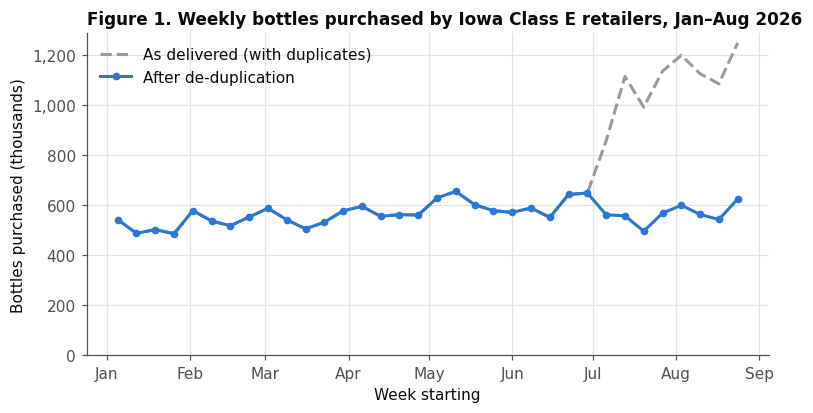

In [9]:
def to_weekly(daily):
    s = daily[(daily.index >= FIRST_WEEK_START) & (daily.index <= LAST_WEEK_END)]
    return s.resample("W-SUN").sum()          # Monday-Sunday weeks, labeled by Sunday

clean_daily_bottles = df.groupby("ordered_on")["sales_bottles"].sum()
w_raw, w_clean = to_weekly(raw_daily_bottles), to_weekly(clean_daily_bottles)
week_start = w_clean.index - pd.Timedelta(days=6)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(week_start, w_raw.values / 1e3, color=GRAY, lw=2, ls="--", label="As delivered (with duplicates)")
ax.plot(week_start, w_clean.values / 1e3, color=BLUE, lw=2, marker="o", ms=4, label="After de-duplication")
ax.set_title("Figure 1. Weekly bottles purchased by Iowa Class E retailers, Jan–Aug 2026", loc="left")
ax.set_xlabel("Week starting")
ax.set_ylabel("Bottles purchased (thousands)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator())
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "fig1_weekly_bottles.png")
plt.show()

weekly_summary = pd.DataFrame({"week_start": week_start.date, "bottles_raw": w_raw.values, "bottles_clean": w_clean.values})
weekly_summary.to_csv(OUT_DIR / "weekly_bottles.csv", index=False)
RESULTS["weekly_bottles_clean"] = {"mean": float(w_clean.mean()), "min": float(w_clean.min()),
                                   "max": float(w_clean.max()), "cv": float(w_clean.std() / w_clean.mean())}

## 10. Weekly aggregation
Invoice lines are rolled up to **store × product × week** net bottles. Only the 34 complete weeks are kept (the partial first and last calendar weeks would understate demand).

In [10]:
wk = df[(df["ordered_on"] >= FIRST_WEEK_START) & (df["ordered_on"] <= LAST_WEEK_END)].copy()
wk["week"] = ((wk["ordered_on"] - FIRST_WEEK_START).dt.days // 7 + 1).astype(int)
N_WEEKS = int(wk["week"].max())
week_starts = FIRST_WEEK_START + pd.to_timedelta(7 * np.arange(N_WEEKS), unit="D")
print(f"Complete weeks: {N_WEEKS}  |  rows in complete weeks: {len(wk):,}  |  rows outside (partial weeks): {len(df) - len(wk):,}")
RESULTS.update(n_weeks=N_WEEKS, rows_in_complete_weeks=int(len(wk)), rows_partial_weeks=int(len(df) - len(wk)))

sp_week = wk.groupby(["store_no", "item_no", "week"])["sales_bottles"].sum().reset_index()
active_pair = sp_week[sp_week["sales_bottles"] > 0]
active_weeks_all = active_pair.groupby(["store_no", "item_no"])["week"].nunique()
n_possible = wk["store_no"].nunique() * wk["item_no"].nunique()
print(f"Store-product pairs with any purchase: {len(active_weeks_all):,} of {n_possible:,} possible ({len(active_weeks_all)/n_possible:.1%})")
print("Active weeks per pair:", active_weeks_all.describe().round(2).to_dict())
RESULTS["pairs_observed"] = int(len(active_weeks_all))
RESULTS["pairs_possible"] = int(n_possible)
RESULTS["pair_active_weeks_median"] = float(active_weeks_all.median())

Complete weeks: 34  |  rows in complete weeks: 1,580,749  |  rows outside (partial weeks): 23,445
Store-product pairs with any purchase: 507,186 of 9,695,405 possible (5.2%)
Active weeks per pair: {'count': 507186.0, 'mean': 3.07, 'std': 3.69, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 34.0}


## 11. Figure 2 — Concentration and intermittency of demand
Two properties drive the modeling design: (a) a small share of products accounts for most bottles, and (b) most store-product pairs buy only occasionally over the 34 weeks.

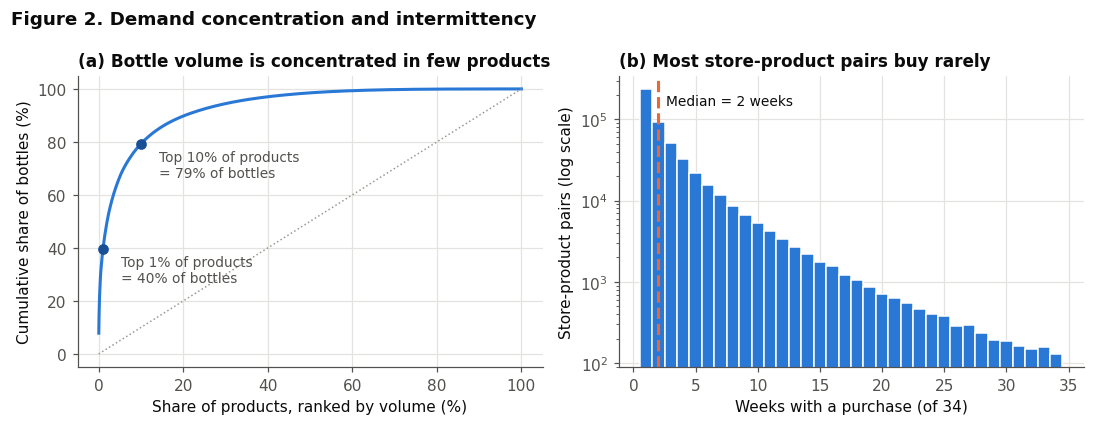

In [11]:
share_products = np.arange(1, len(item_vol) + 1) / len(item_vol)
cum_bottles = item_vol.clip(lower=0).cumsum() / item_vol.clip(lower=0).sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
ax = axes[0]
ax.plot(share_products * 100, cum_bottles.values * 100, color=BLUE, lw=2)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls=":")
for p in [0.01, 0.10]:
    y = cum_bottles.iloc[int(np.ceil(len(cum_bottles) * p)) - 1] * 100
    ax.plot(p * 100, y, "o", color=BLUE_DARK, ms=6)
    ax.annotate(f"Top {p:.0%} of products\n= {y:.0f}% of bottles", (p * 100, y), xytext=(12, -22),
                textcoords="offset points", fontsize=9, color=INK_2)
ax.set_title("(a) Bottle volume is concentrated in few products", loc="left")
ax.set_xlabel("Share of products, ranked by volume (%)")
ax.set_ylabel("Cumulative share of bottles (%)")

ax = axes[1]
bins = np.arange(0.5, N_WEEKS + 1.5, 1)
ax.hist(active_weeks_all.values, bins=bins, color=BLUE, edgecolor="white", linewidth=1)
med = active_weeks_all.median()
ax.axvline(med, color=ORANGE, lw=2, ls="--")
ax.text(med + 0.6, ax.get_ylim()[1] * 0.6, f"Median = {med:.0f} weeks", color=INK, fontsize=9)
ax.set_yscale("log")
ax.set_title("(b) Most store-product pairs buy rarely", loc="left")
ax.set_xlabel(f"Weeks with a purchase (of {N_WEEKS})")
ax.set_ylabel("Store-product pairs (log scale)")
fig.suptitle("Figure 2. Demand concentration and intermittency", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_concentration_intermittency.png")
plt.show()

RESULTS["top1pct_products_share"] = float(cum_bottles.iloc[int(np.ceil(len(cum_bottles) * 0.01)) - 1])
RESULTS["top10pct_products_share"] = float(cum_bottles.iloc[int(np.ceil(len(cum_bottles) * 0.10)) - 1])

## 12. Panel construction (reusable for both grains)
The functions below turn weekly totals into a **dense panel** - one row per series (store-product or store-category), one column per week, with zeros for weeks with no purchase. Zeros matter: "did not order this week" is information the model needs.

**Eligibility rule (rolling, decided at each forecast origin).** A series is forecast at origin *t* only if it purchased in at least `MIN_ACTIVE_WEEKS` = 3 of the `ACTIVITY_WINDOW` = 8 weeks ending at *t* - i.e., it is a *currently regular* buyer.

Why this replaces the proposal's fixed "≥ 12 active weeks" rule: any fixed rule counted over a calendar window selects series *because* they were busy in that window. Counted over the full period it looks into the test weeks; counted over the training weeks it selects series for being busy during the very weeks that supply the training targets, which teaches the model an inflated level that does not persist (selection bias / regression to the mean). A rule decided at each origin from past weeks only is free of both problems and mirrors practice: a distributor forecasts the accounts that are currently buying a product. 3 of 8 weeks (≈ 38%) is close to the proposal's 12 of 36 (≈ 33%).

**Context matrices.** Two extra panels give each series its context: the store's total weekly bottles across *all* products, and the product's (or category's) statewide weekly bottles and number of ordering stores.

In [12]:
def dense_matrix(long_df, keys, value="sales_bottles", n_weeks=None):
    """Pivot long weekly data to a (series x week) matrix; net negatives floored at 0."""
    n_weeks = n_weeks or N_WEEKS
    m = long_df.pivot_table(index=keys, columns="week", values=value, aggfunc="sum", fill_value=0)
    m = m.reindex(columns=range(1, n_weeks + 1), fill_value=0).clip(lower=0)
    return m


def build_panel(level_col):
    """Dense (series x week) matrix for every store-level pair with any purchase, plus context matrices.
    Eligibility is applied later, origin by origin (Section 14)."""
    long = wk.groupby(["store_no", level_col, "week"])["sales_bottles"].sum().reset_index()
    Y = dense_matrix(long, ["store_no", level_col]).astype(np.float32)
    Y = Y[Y.sum(axis=1) > 0]                     # drop pairs whose only lines were returns

    store_m = dense_matrix(wk.groupby(["store_no", "week"])["sales_bottles"].sum().reset_index(), ["store_no"])
    level_long = long.groupby([level_col, "week"])["sales_bottles"].sum().reset_index()
    level_m = dense_matrix(level_long, [level_col])
    level_stores = (long[long["sales_bottles"] > 0].groupby([level_col, "week"])["store_no"].nunique()
                    .rename("n_stores").reset_index())
    level_n = dense_matrix(level_stores, [level_col], value="n_stores")

    keys = Y.index.to_frame(index=False)
    return {
        "level_col": level_col, "keys": keys, "Y": Y.to_numpy(np.float32),
        "S": store_m.to_numpy(np.float32), "L": level_m.to_numpy(np.float32),
        "C": level_n.reindex(level_m.index).fillna(0).to_numpy(np.float32),
        "store_idx": store_m.index.get_indexer(keys["store_no"]),     # row of each series' store in S
        "level_idx": level_m.index.get_indexer(keys[level_col]),      # row of each series' product/category in L, C
    }


panel_sp = build_panel("item_no")
print(f"Store-product pairs in the panel: {len(panel_sp['keys']):,} x {N_WEEKS} weeks")
RESULTS["sp_pairs_in_panel"] = int(len(panel_sp["keys"]))

Store-product pairs in the panel: 507,186 x 34 weeks


## 13. Static attributes
Product attributes (bottle size, pack, shelf price, category) and a store-context attribute (how many licensed stores operate in the store's county, a proxy for urban versus rural markets) are joined to each series.

*Assumption:* product attributes are treated as catalogue information known in advance. They are summarized from weeks 1–26 only (median retail price, most common category/size/pack), so no test-period values enter the features.

In [13]:
train_rows = wk[wk["week"] <= STATIC_END_WEEK]
cat_names = sorted(df["category_name"].unique())
CAT_ID = {c: i for i, c in enumerate(cat_names)}

item_attr = (train_rows.groupby("item_no")
             .agg(bottle_volume_ml=("bottle_volume_ml", "median"), pack=("pack", "median"),
                  retail_price=("state_bottle_retail", "median"),
                  category_name=("category_name", lambda s: s.mode().iat[0])))
item_attr["category_id"] = item_attr["category_name"].map(CAT_ID)

cat_attr = (train_rows.groupby("category_name")
            .agg(bottle_volume_ml=("bottle_volume_ml", "median"), pack=("pack", "median"),
                 retail_price=("state_bottle_retail", "median")))
cat_attr["category_id"] = cat_attr.index.map(CAT_ID)

store_county = df.groupby("store_no")["county_name"].agg(lambda s: s.mode().iat[0])
county_store_count = store_county.value_counts()
store_attr = pd.DataFrame({"county_store_count": store_county.map(county_store_count)})
display(item_attr.describe().round(2))
print("County store counts:", county_store_count.describe().round(1).to_dict())

,bottle_volume_ml,pack,retail_price,category_id
count,4168.00,4168.00,4168.00,4168.00
mean,765.50,9.41,35.76,19.93
std,426.36,6.37,119.64,14.29
min,20.00,1.00,1.46,0.00
25%,750.00,6.00,12.38,7.00
50%,750.00,6.00,21.00,18.00
75%,750.00,12.00,37.50,36.00
max,4500.00,48.00,5625.00,44.00


County store counts: {'count': 100.0, 'mean': 22.0, 'std': 36.9, 'min': 1.0, '25%': 8.0, '50%': 11.5, '75%': 19.2, 'max': 311.0}


## 14. Target definition and feature engineering

**Unit of observation:** one series (store × product, later store × category) at one *forecast origin* week *t*.

**Target:** `target_4w` = total bottles the store buys of that product in weeks *t+1* to *t+4*.

**Why four weeks:** it matches the proposal's research question and a monthly replenishment rhythm, and summing four weeks smooths week-to-week noise from biweekly ordering cycles. It is short enough to be realistic with only 34 weeks of history — long-horizon or annual forecasting is not attempted.

**Leakage control by construction:** `make_features` only ever receives the matrices *sliced to weeks 1…t*. It is physically impossible for it to read a target-period week. Section 15 tests this explicitly.

| Family | Features |
|---|---|
| Series recency & frequency | lags 1–4, 4- and 8-week sums, 8-week mean and std, active weeks in last 4/8, historical active rate, weeks since last purchase, mean order size when active, 4-week trend |
| Store context | store's total bottles last 4/8 weeks, store active weeks last 8, store trend, county store count |
| Product market activity | product's statewide bottles last 4 weeks, avg. stores ordering it per week |
| Product attributes (static) | bottle size, pack, median retail price, category |
| Calendar | month of target window start, federal holidays inside target window |

In [14]:
FEATURE_FAMILY = {
    "lag_1": "Series recency & frequency", "lag_2": "Series recency & frequency",
    "lag_3": "Series recency & frequency", "lag_4": "Series recency & frequency",
    "sum_4w": "Series recency & frequency", "sum_8w": "Series recency & frequency",
    "mean_8w": "Series recency & frequency", "std_8w": "Series recency & frequency",
    "active_4w": "Series recency & frequency", "active_8w": "Series recency & frequency",
    "active_rate_hist": "Series recency & frequency", "weeks_since_last": "Series recency & frequency",
    "mean_when_active_8w": "Series recency & frequency", "trend_4w": "Series recency & frequency",
    "store_sum_4w": "Store context", "store_sum_8w": "Store context",
    "store_active_8w": "Store context", "store_trend_4w": "Store context",
    "county_store_count": "Store context",
    "level_sum_4w": "Product market activity", "level_stores_4w": "Product market activity",
    "bottle_volume_ml": "Product attributes (static)", "pack": "Product attributes (static)",
    "retail_price": "Product attributes (static)", "category_id": "Product attributes (static)",
    "target_month": "Calendar", "holidays_in_target": "Calendar",
}
FEATURES = list(FEATURE_FAMILY)
CAT_FEATURES = ["category_id"]
SIGNED_FEATURES = ["trend_4w", "store_trend_4w"]           # can be negative -> no log transform
LOG_FEATURES = [f for f in FEATURES if f not in CAT_FEATURES + SIGNED_FEATURES]


def make_features(t, Yh, Sh, Lh, Ch):
    """Features at origin t. Every matrix passed in has exactly t columns (weeks 1..t)."""
    assert Yh.shape[1] == t and Sh.shape[1] == t and Lh.shape[1] == t and Ch.shape[1] == t
    last = lambda M, k: M[:, max(0, t - k):t]
    prev = lambda M, k: M[:, max(0, t - 2 * k):max(0, t - k)]
    f = {}
    for k in range(1, 5):
        f[f"lag_{k}"] = Yh[:, t - k]
    f["sum_4w"] = last(Yh, 4).sum(1)
    f["sum_8w"] = last(Yh, 8).sum(1)
    f["mean_8w"] = last(Yh, 8).mean(1)
    f["std_8w"] = last(Yh, 8).std(1)
    f["active_4w"] = (last(Yh, 4) > 0).sum(1)
    f["active_8w"] = (last(Yh, 8) > 0).sum(1)
    f["active_rate_hist"] = (Yh > 0).mean(1)
    pos = Yh > 0
    last_active = t - 1 - np.argmax(pos[:, ::-1], axis=1)          # 0-based column of last purchase
    f["weeks_since_last"] = np.where(pos.any(1), t - 1 - last_active, t)
    f["mean_when_active_8w"] = f["sum_8w"] / np.maximum(f["active_8w"], 1)
    f["trend_4w"] = np.log1p(f["sum_4w"]) - np.log1p(prev(Yh, 4).sum(1))
    f["store_sum_4w"] = last(Sh, 4).sum(1)
    f["store_sum_8w"] = last(Sh, 8).sum(1)
    f["store_active_8w"] = (last(Sh, 8) > 0).sum(1)
    f["store_trend_4w"] = np.log1p(f["store_sum_4w"]) - np.log1p(prev(Sh, 4).sum(1))
    f["level_sum_4w"] = last(Lh, 4).sum(1)
    f["level_stores_4w"] = last(Ch, 4).mean(1)
    return f


def target_calendar(t):
    """Calendar facts about the target window (known in advance)."""
    start = FIRST_WEEK_START + pd.Timedelta(weeks=t)                   # Monday of week t+1
    end = start + pd.Timedelta(weeks=HORIZON) - pd.Timedelta(days=1)
    return {"target_month": start.month,
            "holidays_in_target": int(((HOLIDAYS_2026 >= start) & (HOLIDAYS_2026 <= end)).sum()),
            "target_start": start}


def croston_sba(Y, alpha=0.1):
    """Croston's method with the Syntetos-Boylan correction, run forward through time.
    Column j of the result is the per-week forecast using weeks 1..j+1 only."""
    n, T = Y.shape
    z, p = np.zeros(n), np.zeros(n)
    q = np.ones(n)                                                     # periods since last demand
    init = np.zeros(n, dtype=bool)
    F = np.zeros((n, T))
    for j in range(T):
        y = Y[:, j]
        d = y > 0
        first, later = d & ~init, d & init
        z[first], p[first] = y[first], q[first]
        z[later] += alpha * (y[later] - z[later])
        p[later] += alpha * (q[later] - p[later])
        init |= d
        q = np.where(d, 1, q + 1)
        F[:, j] = np.where(init, (1 - alpha / 2) * z / np.maximum(p, 1e-9), 0)
    return F


def origin_frame(t, panel, static_level, F_croston, Y=None, S=None, L=None, C=None):
    """Modeling rows for one forecast origin t. Every input is sliced to weeks 1..t before use,
    except the target, which is read separately from weeks t+1..t+HORIZON."""
    Y = panel["Y"] if Y is None else Y
    S = panel["S"] if S is None else S
    L = panel["L"] if L is None else L
    C = panel["C"] if C is None else C
    level_col, keys = panel["level_col"], panel["keys"]
    hist = Y[:, :t]
    eligible = (hist[:, max(0, t - ACTIVITY_WINDOW):t] > 0).sum(1) >= MIN_ACTIVE_WEEKS   # past-only rule
    idx = np.flatnonzero(eligible)
    f = make_features(t, hist[idx].astype(float), S[panel["store_idx"][idx], :t].astype(float),
                      L[panel["level_idx"][idx], :t].astype(float), C[panel["level_idx"][idx], :t].astype(float))
    cal = target_calendar(t)
    frame = pd.DataFrame(f)
    frame["county_store_count"] = store_attr["county_store_count"].reindex(keys["store_no"].iloc[idx]).to_numpy()
    lvl = static_level.reindex(keys[level_col].iloc[idx])
    for c in ["bottle_volume_ml", "pack", "retail_price", "category_id"]:
        frame[c] = lvl[c].to_numpy()
    frame["target_month"] = cal["target_month"]
    frame["holidays_in_target"] = cal["holidays_in_target"]
    # --- baselines (predictions, not features) ---
    frame["pred_naive_4w"] = f["sum_4w"]                    # last 4 weeks carried forward
    frame["pred_ma8_4w"] = f["mean_8w"] * HORIZON           # 8-week moving average x 4
    frame["pred_croston_4w"] = F_croston[idx, t - 1] * HORIZON
    # --- target and identifiers ---
    future = Y[:, t:t + HORIZON].sum(1)
    frame["target_4w"] = future[idx].astype(float)
    frame["origin"] = t
    frame["target_start"] = cal["target_start"]
    frame["series_id"] = idx
    frame["store_no"] = keys["store_no"].iloc[idx].to_numpy()
    frame[level_col] = keys[level_col].iloc[idx].to_numpy()
    coverage = {"origin": t, "eligible_series": int(len(idx)),
                "share_of_target_bottles": float(future[idx].sum() / max(future.sum(), 1))}
    return frame, coverage


def build_dataset(panel, static_level):
    F_croston = croston_sba(panel["Y"])
    frames, cov = [], []
    for t in range(FIRST_ORIGIN, N_WEEKS - HORIZON + 1):
        frame, c = origin_frame(t, panel, static_level, F_croston)
        frames.append(frame)
        cov.append(c)
    data = pd.concat(frames, ignore_index=True)
    data[FEATURES] = data[FEATURES].astype(float)
    data["category_id"] = data["category_id"].fillna(-1).astype(int)
    return data, pd.DataFrame(cov), F_croston


t0 = time.time()
data_sp, coverage_sp, croston_sp = build_dataset(panel_sp, item_attr)
print(f"Store-product modeling table: {data_sp.shape[0]:,} rows x {len(FEATURES)} features "
      f"({data_sp['origin'].nunique()} origins, {data_sp['series_id'].nunique():,} distinct series)  [{time.time()-t0:.1f}s]")
print("Missing feature values:", int(data_sp[FEATURES].isna().sum().sum()))
display(coverage_sp.describe().round(3))
display(data_sp[FEATURES + ["target_4w"]].describe().T.round(2))
coverage_sp.to_csv(OUT_DIR / "eligibility_coverage_store_product.csv", index=False)
RESULTS.update(sp_model_rows=int(len(data_sp)), sp_distinct_series=int(data_sp["series_id"].nunique()),
               sp_eligible_per_origin_mean=float(coverage_sp["eligible_series"].mean()),
               sp_target_bottle_coverage_mean=float(coverage_sp["share_of_target_bottles"].mean()),
               sp_zero_target_share=float((data_sp["target_4w"] == 0).mean()))

Store-product modeling table: 708,074 rows x 27 features (23 origins, 79,971 distinct series)  [1.3s]
Missing feature values: 0


,origin,eligible_series,share_of_target_bottles
count,23.000,23.000,23.000
mean,19.000,30785.826,0.368
std,6.782,2355.520,0.010
min,8.000,26920.000,0.353
25%,13.500,29050.500,0.360
50%,19.000,30947.000,0.366
75%,24.500,32772.000,0.373
max,30.000,34766.000,0.387


,count,mean,std,min,25%,50%,75%,max
lag_1,708074.0,8.52,35.45,0.00,0.00,1.00,8.00,10560.00
lag_2,708074.0,8.01,32.47,0.00,0.00,0.00,6.00,5760.00
lag_3,708074.0,7.85,32.18,0.00,0.00,0.00,6.00,5760.00
lag_4,708074.0,7.89,31.93,0.00,0.00,0.00,6.00,5760.00
sum_4w,708074.0,32.27,95.83,0.00,6.00,12.00,24.00,15180.00
sum_8w,708074.0,62.78,174.77,3.00,12.00,29.00,60.00,19260.00
mean_8w,708074.0,7.85,21.85,0.38,1.50,3.62,7.50,2407.50
std_8w,708074.0,7.65,21.49,0.00,1.73,3.97,6.32,4295.35
active_4w,708074.0,1.98,0.89,0.00,1.00,2.00,2.00,4.00
active_8w,708074.0,3.93,1.28,3.00,3.00,3.00,4.00,8.00


## 15. Temporal leakage checks
Two explicit tests:
1. **Future-perturbation test.** Scramble every week after origin *t* (series, store, and product matrices) and rebuild that origin. If the eligible set, any feature, or any baseline changes, it was reading the future. Only the target may change.
2. **Split test.** The last training target window must end on or before the first test origin, so no training label overlaps the test period.

In [15]:
rng = np.random.default_rng(SEED)
t_chk = TEST_ORIGINS[0]
scramble = lambda M: np.concatenate([M[:, :t_chk], rng.poisson(50, size=M[:, t_chk:].shape).astype(M.dtype)], axis=1)
Ys, Ss, Ls, Cs = (scramble(panel_sp[k]) for k in ["Y", "S", "L", "C"])
F_scr = croston_sba(Ys)
fr_true, _ = origin_frame(t_chk, panel_sp, item_attr, croston_sp)
fr_scr, _ = origin_frame(t_chk, panel_sp, item_attr, F_scr, Y=Ys, S=Ss, L=Ls, C=Cs)
check_cols = FEATURES + ["pred_naive_4w", "pred_ma8_4w", "pred_croston_4w", "series_id"]
assert len(fr_true) == len(fr_scr), "LEAKAGE: eligibility changed when the future changed"
assert np.allclose(fr_true[check_cols].fillna(-9).to_numpy(float), fr_scr[check_cols].fillna(-9).to_numpy(float)), \
    "LEAKAGE: features or baselines changed when the future changed"
assert not np.allclose(fr_true["target_4w"], fr_scr["target_4w"])   # sanity: the target did change
print(f"Future-perturbation test passed at origin {t_chk}: eligibility, features, and baselines "
      f"depend only on weeks <= {t_chk} (the target changed, as it should).")
del Ys, Ss, Ls, Cs, F_scr

assert TRAIN_LAST_ORIGIN + HORIZON <= TEST_ORIGINS[0]
print(f"Split test passed: last training target window ends in week {TRAIN_LAST_ORIGIN + HORIZON}; "
      f"first test origin is week {TEST_ORIGINS[0]}.")
RESULTS["leakage_tests_passed"] = True

Future-perturbation test passed at origin 26: eligibility, features, and baselines depend only on weeks <= 26 (the target changed, as it should).
Split test passed: last training target window ends in week 26; first test origin is week 26.


## 16. Chronological train / test split
- **Training origins 8–22** - target windows fall in weeks 9–26 (early March–early July).
- **Embargo origins 23–25** - dropped, because their target windows would overlap the test period.
- **Test origins 26–30** - target windows cover weeks 27–34 (July–August), which the models never see.

A random split is not used: it would let the model learn from July to "predict" March.

In [16]:
def split(data):
    tr = data[data["origin"] <= TRAIN_LAST_ORIGIN].reset_index(drop=True)
    te = data[data["origin"].isin(TEST_ORIGINS)].reset_index(drop=True)
    return tr, te


train_sp, test_sp = split(data_sp)
for name, d in [("train", train_sp), ("test", test_sp)]:
    print(f"{name:5s}: {len(d):>9,} rows | origins {d['origin'].min()}-{d['origin'].max()} | "
          f"target windows start {d['target_start'].min().date()} to {d['target_start'].max().date()} | "
          f"zero-target share {(d['target_4w'] == 0).mean():.1%}")
RESULTS["sp_train_rows"], RESULTS["sp_test_rows"] = int(len(train_sp)), int(len(test_sp))
RESULTS["sp_test_zero_share"] = float((test_sp["target_4w"] == 0).mean())

train:   440,649 rows | origins 8-22 | target windows start 2026-03-02 to 2026-06-08 | zero-target share 19.3%
test :   168,578 rows | origins 26-30 | target windows start 2026-07-06 to 2026-08-03 | zero-target share 22.2%


## 17. Baselines, models, and metrics

**Baselines** (what a planner could do with a spreadsheet):
- *Naive carry-forward* - next four weeks = last four weeks. This is the benchmark for H1.
- *8-week moving average × 4.*
- *Croston-SBA* - the classic method for intermittent demand (Croston, 1972; Syntetos & Boylan, 2005).

**Models** - each included for a specific reason:
- *Poisson regression (GLM)* - the simplest model built for non-negative counts; interpretable; tests whether a linear combination of history already beats the baselines.
- *Random forest* - captures non-linear effects and interactions (e.g., "large store × sporadic product") without distributional assumptions.
- *Histogram gradient boosting, Poisson loss* - the approach that has dominated recent retail forecasting competitions (Makridakis et al., 2022); the Poisson loss respects the count nature of the target.

**Metrics.** MAE (bottles), RMSE (penalizes large misses), **WAPE** = Σ|error| / Σ actual (scale-free, safe with zeros, comparable across grains), R², bias (% over/under-forecast), and **relative MAE** = model MAE ÷ naive MAE (below 1 means the model beats the naive rule). MAPE is not used because many targets are zero (Hyndman & Koehler, 2006).

**Model selection** uses rolling-origin cross-validation on the training period only (Bergmeir & Benítez, 2012); the test period is used once, for the final report.

In [17]:
BASELINES = {"Naive (last 4 wks)": "pred_naive_4w", "8-wk moving avg": "pred_ma8_4w", "Croston-SBA": "pred_croston_4w"}


def make_models():
    pre = ColumnTransformer([
        ("log", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), LOG_FEATURES),
        ("signed", StandardScaler(), SIGNED_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])
    return {
        "Poisson GLM": make_pipeline(pre, PoissonRegressor(alpha=1e-4, solver="newton-cholesky", max_iter=300)),
        "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=0.5,
                                               max_samples=0.25, n_jobs=-1, random_state=SEED),
        "Gradient boosting (Poisson)": HistGradientBoostingRegressor(
            loss="poisson", learning_rate=0.05, max_iter=400, max_leaf_nodes=31, min_samples_leaf=50,
            l2_regularization=1.0, categorical_features=[FEATURES.index("category_id")],
            early_stopping=False, random_state=SEED),
    }


def metrics(y, p, naive_mae=None):
    p = np.clip(p, 0, None)
    out = {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))),
           "WAPE_%": float(np.abs(y - p).sum() / y.sum() * 100), "R2": r2_score(y, p),
           "Bias_%": float((p.sum() - y.sum()) / y.sum() * 100)}
    out["Rel_MAE_vs_naive"] = out["MAE"] / naive_mae if naive_mae else np.nan
    return out


def evaluate_all(test_df, preds):
    naive_mae = mean_absolute_error(test_df["target_4w"], test_df["pred_naive_4w"])
    rows = [{"Method": n, "Type": "Baseline", **metrics(test_df["target_4w"].to_numpy(), test_df[c].to_numpy(), naive_mae)}
            for n, c in BASELINES.items()]
    rows += [{"Method": n, "Type": "Model", **metrics(test_df["target_4w"].to_numpy(), p, naive_mae)}
             for n, p in preds.items()]
    return pd.DataFrame(rows)

## 18. Rolling-origin cross-validation (training period only)
Three expanding-window folds. Each fold trains on origins up to a cutoff and validates on the next three origins, leaving a four-week gap so training targets never overlap validation weeks. This is the evidence used to pick the "best model" before touching the test set. *(Runtime: several minutes; the random forest is the slowest step.)*

In [18]:
def rolling_cv(train_df, label):
    rows = []
    for k, fold in enumerate(CV_FOLDS, 1):
        tr = train_df[train_df["origin"] <= fold["train_max"]]
        va = train_df[train_df["origin"].isin(fold["val"])]
        naive_mae = mean_absolute_error(va["target_4w"], va["pred_naive_4w"])
        for n, c in BASELINES.items():
            rows.append({"fold": k, "Method": n, **metrics(va["target_4w"].to_numpy(), va[c].to_numpy(), naive_mae)})
        for n, m in make_models().items():
            t0 = time.time()
            m.fit(tr[FEATURES], tr["target_4w"])
            rows.append({"fold": k, "Method": n, **metrics(va["target_4w"].to_numpy(), m.predict(va[FEATURES]), naive_mae)})
            print(f"[{label}] fold {k} {n}: {time.time()-t0:.0f}s")
    cv = pd.DataFrame(rows)
    summary = cv.groupby("Method")[["MAE", "WAPE_%", "Rel_MAE_vs_naive"]].agg(["mean", "std"]).round(3)
    return cv, summary


cv_sp, cv_sp_summary = rolling_cv(train_sp, "store-product")
display(cv_sp_summary.sort_values(("MAE", "mean")))
cv_sp.to_csv(OUT_DIR / "cv_folds_store_product.csv", index=False)
model_names = list(make_models())
best_sp = cv_sp[cv_sp["Method"].isin(model_names)].groupby("Method")["MAE"].mean().idxmin()
print("Best model by mean CV MAE (store-product):", best_sp)
RESULTS["sp_cv_summary"] = {m: {"MAE_mean": float(g["MAE"].mean()), "MAE_std": float(g["MAE"].std()),
                                "WAPE_mean": float(g["WAPE_%"].mean()), "RelMAE_mean": float(g["Rel_MAE_vs_naive"].mean())}
                            for m, g in cv_sp.groupby("Method")}
RESULTS["sp_best_model_by_cv"] = best_sp

[store-product] fold 1 Poisson GLM: 2s
[store-product] fold 1 Random forest: 1s
[store-product] fold 1 Gradient boosting (Poisson): 1s
[store-product] fold 2 Poisson GLM: 1s
[store-product] fold 2 Random forest: 2s
[store-product] fold 2 Gradient boosting (Poisson): 2s
[store-product] fold 3 Poisson GLM: 1s
[store-product] fold 3 Random forest: 4s
[store-product] fold 3 Gradient boosting (Poisson): 3s


MAE         WAPE_%        Rel_MAE_vs_naive  \
                               mean    std    mean    std             mean   
Method                                                                       
Gradient boosting (Poisson)  13.572  0.227  47.365  0.979            0.789   
Random forest                13.767  0.243  48.040  0.629            0.801   
Poisson GLM                  13.831  0.309  48.282  1.921            0.805   
Croston-SBA                  14.513  0.580  50.620  0.579            0.844   
8-wk moving avg              14.882  0.125  51.941  1.212            0.866   
Naive (last 4 wks)           17.192  0.123  60.000  1.277            1.000   

                                    
                               std  
Method                              
Gradient boosting (Poisson)  0.011  
Random forest                0.009  
Poisson GLM                  0.021  
Croston-SBA                  0.028  
8-wk moving avg              0.006  
Naive (last 4 wks)           0.000

Best model by mean CV MAE (store-product): Gradient boosting (Poisson)


## 19. Final training and held-out test evaluation - store-product grain
Each model is refit on all training origins (8–22) and evaluated once on test origins 26–30.

In [19]:
def fit_and_test(train_df, test_df, label):
    fitted, preds = {}, {}
    for n, m in make_models().items():
        t0 = time.time()
        m.fit(train_df[FEATURES], train_df["target_4w"])
        fitted[n], preds[n] = m, np.clip(m.predict(test_df[FEATURES]), 0, None)
        print(f"[{label}] {n} fit in {time.time()-t0:.0f}s")
    table = evaluate_all(test_df, preds).round(3)
    return fitted, preds, table


models_sp, preds_sp, test_table_sp = fit_and_test(train_sp, test_sp, "store-product")
display(test_table_sp)
test_table_sp.to_csv(OUT_DIR / "test_metrics_store_product.csv", index=False)
RESULTS["sp_test_metrics"] = test_table_sp.set_index("Method").to_dict(orient="index")

[store-product] Poisson GLM fit in 2s
[store-product] Random forest fit in 8s
[store-product] Gradient boosting (Poisson) fit in 5s


,Method,Type,MAE,RMSE,WAPE_%,R2,Bias_%,Rel_MAE_vs_naive
0,Naive (last 4 wks),Baseline,16.303,80.885,64.176,0.389,21.725,1.000
1,8-wk moving avg,Baseline,14.226,71.770,56.002,0.519,19.780,0.873
2,Croston-SBA,Baseline,12.838,63.945,50.537,0.618,1.870,0.787
3,Poisson GLM,Model,13.728,71.318,54.039,0.525,17.139,0.842
4,Random forest,Model,12.749,70.406,50.188,0.537,6.664,0.782
5,Gradient boosting (Poisson),Model,12.862,66.983,50.633,0.581,8.565,0.789


## 20. Store-category grain (RQ3 / H3)
The identical pipeline - same eligibility rule, features, split, baselines, models, and metrics - is re-run with **category** in place of product. Because bottle totals are larger at this grain, compare grains with the scale-free metrics (WAPE and relative MAE), not raw MAE.

In [20]:
panel_sc = build_panel("category_name")
print(f"Store-category pairs in the panel: {len(panel_sc['keys']):,} x {N_WEEKS} weeks")
data_sc, coverage_sc, croston_sc = build_dataset(panel_sc, cat_attr)
coverage_sc.to_csv(OUT_DIR / "eligibility_coverage_store_category.csv", index=False)
print(f"Store-category modeling table: {len(data_sc):,} rows; mean eligible series per origin "
      f"{coverage_sc['eligible_series'].mean():,.0f}; mean share of target bottles covered "
      f"{coverage_sc['share_of_target_bottles'].mean():.1%}")
train_sc, test_sc = split(data_sc)
print(f"train {len(train_sc):,} rows | test {len(test_sc):,} rows")

cv_sc, cv_sc_summary = rolling_cv(train_sc, "store-category")
display(cv_sc_summary.sort_values(("MAE", "mean")))
cv_sc.to_csv(OUT_DIR / "cv_folds_store_category.csv", index=False)
best_sc = cv_sc[cv_sc["Method"].isin(model_names)].groupby("Method")["MAE"].mean().idxmin()
print("Best model by mean CV MAE (store-category):", best_sc)

models_sc, preds_sc, test_table_sc = fit_and_test(train_sc, test_sc, "store-category")
display(test_table_sc)
test_table_sc.to_csv(OUT_DIR / "test_metrics_store_category.csv", index=False)

RESULTS.update(sc_pairs_in_panel=int(len(panel_sc["keys"])), sc_model_rows=int(len(data_sc)),
               sc_eligible_per_origin_mean=float(coverage_sc["eligible_series"].mean()),
               sc_target_bottle_coverage_mean=float(coverage_sc["share_of_target_bottles"].mean()),
               sc_zero_target_share=float((data_sc["target_4w"] == 0).mean()),
               sc_train_rows=int(len(train_sc)), sc_test_rows=int(len(test_sc)),
               sc_best_model_by_cv=best_sc,
               sc_cv_summary={m: {"MAE_mean": float(g["MAE"].mean()), "WAPE_mean": float(g["WAPE_%"].mean()),
                                  "RelMAE_mean": float(g["Rel_MAE_vs_naive"].mean())} for m, g in cv_sc.groupby("Method")},
               sc_test_metrics=test_table_sc.set_index("Method").to_dict(orient="index"))

Store-category pairs in the panel: 57,499 x 34 weeks
Store-category modeling table: 501,890 rows; mean eligible series per origin 21,821; mean share of target bottles covered 87.5%
train 321,698 rows | test 113,028 rows
[store-category] fold 1 Poisson GLM: 0s
[store-category] fold 1 Random forest: 1s
[store-category] fold 1 Gradient boosting (Poisson): 1s
[store-category] fold 2 Poisson GLM: 0s
[store-category] fold 2 Random forest: 2s
[store-category] fold 2 Gradient boosting (Poisson): 2s
[store-category] fold 3 Poisson GLM: 1s
[store-category] fold 3 Random forest: 3s
[store-category] fold 3 Gradient boosting (Poisson): 2s


MAE         WAPE_%        Rel_MAE_vs_naive  \
                               mean    std    mean    std             mean   
Method                                                                       
Random forest                41.680  0.410  43.427  0.644            0.843   
Poisson GLM                  42.107  0.662  43.880  1.308            0.852   
Gradient boosting (Poisson)  42.109  0.416  43.877  0.959            0.852   
Croston-SBA                  42.245  1.797  43.995  1.056            0.854   
8-wk moving avg              42.571  0.465  44.353  0.398            0.861   
Naive (last 4 wks)           49.445  0.280  51.520  0.921            1.000   

                                    
                               std  
Method                              
Random forest                0.012  
Poisson GLM                  0.018  
Gradient boosting (Poisson)  0.013  
Croston-SBA                  0.036  
8-wk moving avg              0.008  
Naive (last 4 wks)           0.000

Best model by mean CV MAE (store-category): Random forest
[store-category] Poisson GLM fit in 1s
[store-category] Random forest fit in 6s
[store-category] Gradient boosting (Poisson) fit in 4s


,Method,Type,MAE,RMSE,WAPE_%,R2,Bias_%,Rel_MAE_vs_naive
0,Naive (last 4 wks),Baseline,46.719,142.910,53.808,0.645,8.490,1.000
1,8-wk moving avg,Baseline,40.217,122.437,46.320,0.739,8.726,0.861
2,Croston-SBA,Baseline,36.134,112.618,41.617,0.779,0.406,0.773
3,Poisson GLM,Model,43.490,120.738,50.089,0.746,20.287,0.931
4,Random forest,Model,39.591,126.860,45.598,0.720,10.533,0.847
5,Gradient boosting (Poisson),Model,38.807,121.059,44.696,0.745,8.194,0.831


## 21. Figure 3 - Model performance against baselines, both grains
WAPE on the held-out test weeks (lower is better). Gray bars are spreadsheet-style baselines; blue bars are the models; the darker blue bar is the model chosen by cross-validation.

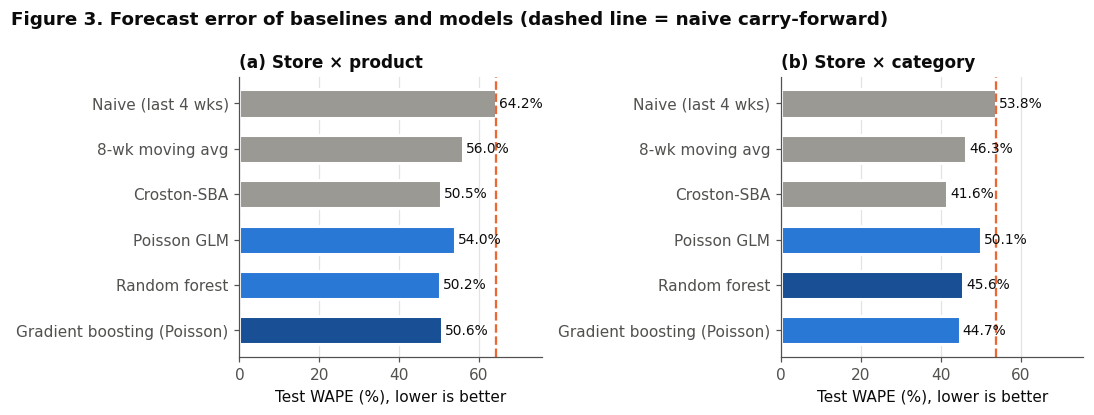

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
x_max = max(test_table_sp["WAPE_%"].max(), test_table_sc["WAPE_%"].max()) * 1.18
for ax, table, best, title in [(axes[0], test_table_sp, best_sp, "(a) Store × product"),
                               (axes[1], test_table_sc, best_sc, "(b) Store × category")]:
    t = table.iloc[::-1]
    colors = [GRAY if ty == "Baseline" else (BLUE_DARK if m == best else BLUE) for m, ty in zip(t["Method"], t["Type"])]
    bars = ax.barh(t["Method"], t["WAPE_%"], color=colors, height=0.62, edgecolor="white", linewidth=2)
    for b, v in zip(bars, t["WAPE_%"]):
        ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9, color=INK)
    naive = table.loc[table["Method"] == "Naive (last 4 wks)", "WAPE_%"].iat[0]
    ax.axvline(naive, color=ORANGE, lw=1.5, ls="--")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Test WAPE (%), lower is better")
    ax.set_xlim(0, x_max)
    ax.grid(axis="y", visible=False)
axes[1].tick_params(labelleft=True)
fig.suptitle("Figure 3. Forecast error of baselines and models (dashed line = naive carry-forward)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_model_comparison.png")
plt.show()

## 22. Figure 4 - Actual vs. predicted demand on the held-out weeks (store-product, best model)
Panel (a) shows every test forecast; points on the diagonal are perfect forecasts. Panel (b) sums all eligible series for each test window — the view a distributor would see when planning total volume - and compares the model with the naive rule.

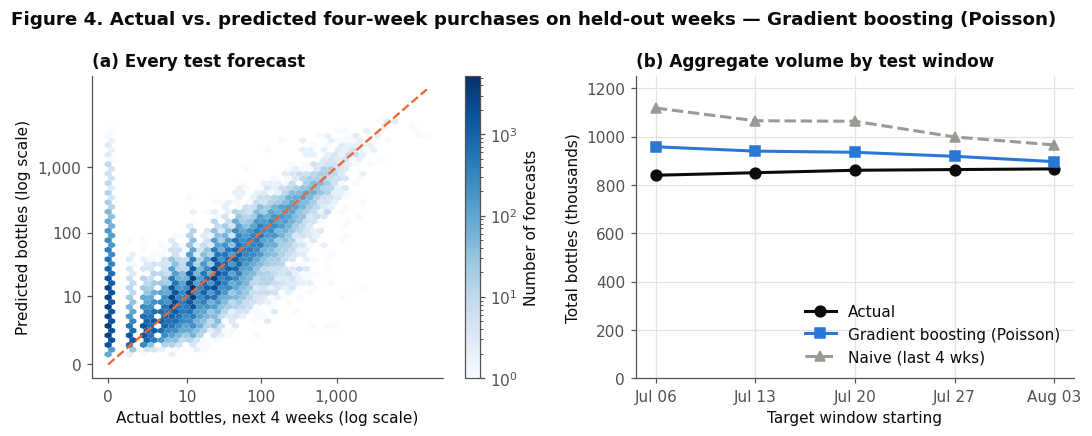

In [22]:
p_best = preds_sp[best_sp]
y_te = test_sp["target_4w"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
hb = ax.hexbin(np.log1p(y_te), np.log1p(p_best), gridsize=45, bins="log", cmap="Blues", mincnt=1, linewidths=0)
lim = np.log1p(max(y_te.max(), p_best.max()))
ax.plot([0, lim], [0, lim], color=ORANGE, lw=1.5, ls="--")
ticks = np.array([0, 10, 100, 1000])
ticks = ticks[np.log1p(ticks) <= lim]
ax.set_xticks(np.log1p(ticks), [f"{v:,}" for v in ticks])
ax.set_yticks(np.log1p(ticks), [f"{v:,}" for v in ticks])
ax.set_xlabel("Actual bottles, next 4 weeks (log scale)")
ax.set_ylabel("Predicted bottles (log scale)")
ax.set_title("(a) Every test forecast", loc="left")
fig.colorbar(hb, ax=ax, label="Number of forecasts")
ax.grid(False)

ax = axes[1]
agg = (test_sp.assign(model=p_best).groupby("target_start")[["target_4w", "model", "pred_naive_4w"]].sum() / 1e3)
ax.plot(agg.index, agg["target_4w"], color=INK, lw=2, marker="o", ms=7, label="Actual")
ax.plot(agg.index, agg["model"], color=BLUE, lw=2, marker="s", ms=7, label=best_sp)
ax.plot(agg.index, agg["pred_naive_4w"], color=GRAY, lw=2, ls="--", marker="^", ms=7, label="Naive (last 4 wks)")
ax.set_ylabel("Total bottles (thousands)")
ax.set_xlabel("Target window starting")
ax.set_title("(b) Aggregate volume by test window", loc="left")
ax.set_xticks(agg.index, [d.strftime("%b %d") for d in agg.index])
ax.set_ylim(0, agg.to_numpy().max() * 1.12)        # zero baseline so gaps are not exaggerated
ax.legend(loc="lower right")
fig.suptitle(f"Figure 4. Actual vs. predicted four-week purchases on held-out weeks — {best_sp}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_actual_vs_predicted.png")
plt.show()
agg.round(2).to_csv(OUT_DIR / "aggregate_by_test_window.csv")
RESULTS["sp_aggregate_by_window_thousands"] = {str(k.date()): v for k, v in agg.round(2).to_dict(orient="index").items()}

## 23. Error analysis
Where does the model help and where does it struggle? Test errors are broken down by **series volume** (quartiles of average weekly bottles in the 8 weeks before the origin), **store size** (quartiles of store volume in weeks 1–26), and **county store density** (a rural–urban proxy). The naive baseline is shown beside the model in every segment.


=== Series volume ===


,rows,actual_mean,MAE_model,MAE_naive,WAPE_model_%,WAPE_naive_%
Series volume,,,,,,
Q1 (lowest),42145,2.54,1.99,2.47,78.45,97.36
Q2,42144,7.53,4.88,6.26,64.85,83.15
Q3,42144,15.41,8.86,11.40,57.48,73.97
Q4 (highest),42145,76.14,35.72,45.08,46.91,59.21



=== Store size ===


,rows,actual_mean,MAE_model,MAE_naive,WAPE_model_%,WAPE_naive_%
Store size,,,,,,
Q1 (lowest),42158,16.17,9.11,12.19,56.32,75.43
Q2,42277,21.45,10.32,13.39,48.12,62.46
Q3,42093,22.81,11.11,13.31,48.70,58.34
Q4 (highest),42050,41.24,20.94,26.34,50.78,63.88



=== County density ===


,rows,actual_mean,MAE_model,MAE_naive,WAPE_model_%,WAPE_naive_%
County density,,,,,,
Low,56193,18.76,10.28,13.22,54.81,70.48
Medium,56192,24.23,13.01,17.20,53.69,70.97
High,56193,33.22,15.29,18.49,46.04,55.66


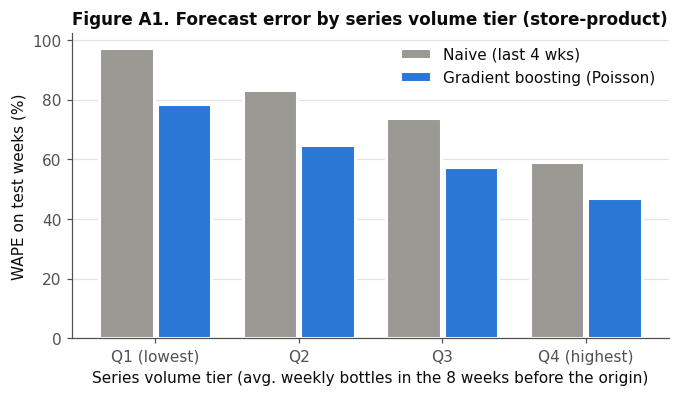

In [23]:
store_train_vol = wk[wk["week"] <= STATIC_END_WEEK].groupby("store_no")["sales_bottles"].sum()
tier_labels = ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]

ea = test_sp[["series_id", "store_no", "target_4w", "pred_naive_4w", "county_store_count", "mean_8w"]].copy()
ea["model"] = p_best
ea["Series volume"] = pd.qcut(ea["mean_8w"].rank(method="first"), 4, labels=tier_labels)
ea["Store size"] = pd.qcut(ea["store_no"].map(store_train_vol), 4, labels=tier_labels)
ea["County density"] = pd.qcut(ea["county_store_count"].rank(method="first"), 3, labels=["Low", "Medium", "High"])


def seg_table(col):
    g = ea.groupby(col, observed=True)
    return pd.DataFrame({
        "rows": g.size(),
        "actual_mean": g["target_4w"].mean(),
        "MAE_model": g.apply(lambda d: np.abs(d["target_4w"] - d["model"]).mean()),
        "MAE_naive": g.apply(lambda d: np.abs(d["target_4w"] - d["pred_naive_4w"]).mean()),
        "WAPE_model_%": g.apply(lambda d: np.abs(d["target_4w"] - d["model"]).sum() / d["target_4w"].sum() * 100),
        "WAPE_naive_%": g.apply(lambda d: np.abs(d["target_4w"] - d["pred_naive_4w"]).sum() / d["target_4w"].sum() * 100),
    }).round(2)


segments = {c: seg_table(c) for c in ["Series volume", "Store size", "County density"]}
for c, t in segments.items():
    print(f"\n=== {c} ===")
    display(t)
pd.concat(segments, names=["segment", "tier"]).to_csv(OUT_DIR / "error_by_segment.csv")
RESULTS["sp_error_by_segment"] = {c: t.to_dict(orient="index") for c, t in segments.items()}

# Appendix Figure A1: WAPE by series-volume tier
t = segments["Series volume"]
x = np.arange(len(t))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x - 0.2, t["WAPE_naive_%"], width=0.38, color=GRAY, label="Naive (last 4 wks)", edgecolor="white", linewidth=2)
ax.bar(x + 0.2, t["WAPE_model_%"], width=0.38, color=BLUE, label=best_sp, edgecolor="white", linewidth=2)
ax.set_xticks(x, [str(i) for i in t.index])
ax.set_xlabel("Series volume tier (avg. weekly bottles in the 8 weeks before the origin)")
ax.set_ylabel("WAPE on test weeks (%)")
ax.set_title("Figure A1. Forecast error by series volume tier (store-product)", loc="left")
ax.legend()
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "figA1_error_by_volume_tier.png")
plt.show()

## 24. Figure 5 - What drives the predictions? (RQ2 / H2)
**Permutation importance** measures how much test MAE worsens when one feature's values are shuffled, breaking its link to the target. It is model-agnostic and computed on held-out data (Breiman, 2001). A **grouped** version shuffles a whole feature family at once, which directly tests H2 (recency/frequency vs. static product attributes) and avoids splitting credit between correlated features such as `sum_4w` and `sum_8w`. Importance describes what the model relies on; it is association, not causation.

Permutation importance computed in 16s


,feature,importance,std,family
5,sum_8w,16.4162,0.0768,Series recency & frequency
9,active_8w,3.3332,0.0402,Series recency & frequency
10,active_rate_hist,1.4696,0.0592,Series recency & frequency
13,trend_4w,0.5032,0.0426,Series recency & frequency
0,lag_1,0.4489,0.0053,Series recency & frequency
20,level_stores_4w,0.3595,0.0358,Product market activity
7,std_8w,0.2851,0.0074,Series recency & frequency
8,active_4w,0.1965,0.0273,Series recency & frequency
19,level_sum_4w,0.1893,0.0574,Product market activity
24,category_id,0.1584,0.1436,Product attributes (static)


,family,n_features,MAE_increase,std
0,Series recency & frequency,14,20.0608,0.1059
3,Product attributes (static),4,0.3876,0.0789
2,Product market activity,2,0.2020,0.0588
1,Store context,5,0.0811,0.0819
4,Calendar,2,0.0000,0.0000


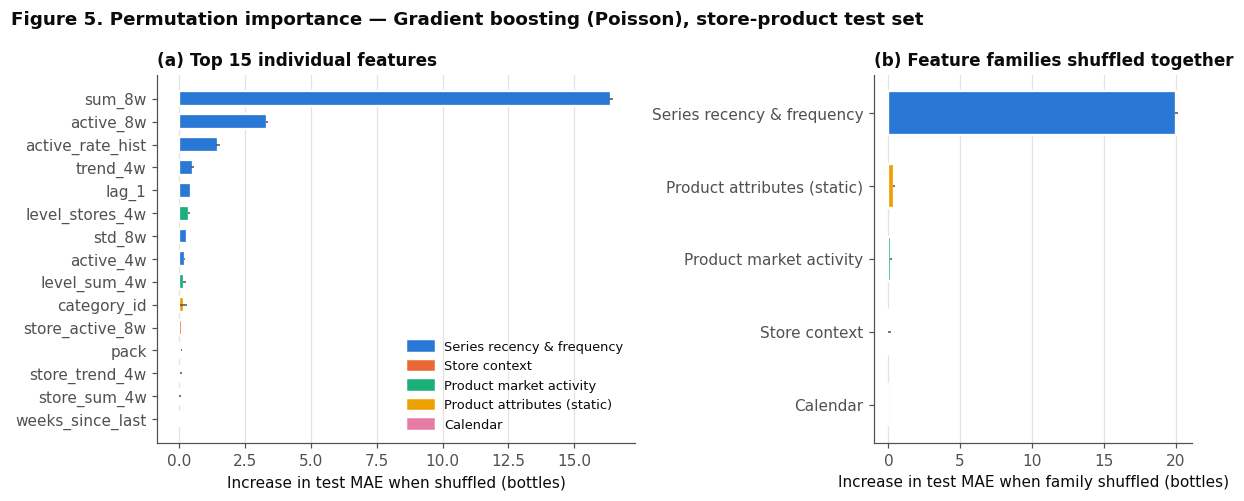

In [24]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(test_sp), size=min(40_000, len(test_sp)), replace=False)
X_s = test_sp.loc[sample_idx, FEATURES].reset_index(drop=True)
y_s = test_sp.loc[sample_idx, "target_4w"].to_numpy()
best_model = models_sp[best_sp]

t0 = time.time()
pi = permutation_importance(best_model, X_s, y_s, scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std})
       .assign(family=lambda d: d["feature"].map(FEATURE_FAMILY))
       .sort_values("importance", ascending=False))
print(f"Permutation importance computed in {time.time()-t0:.0f}s")

base_mae = mean_absolute_error(y_s, np.clip(best_model.predict(X_s), 0, None))
fam_rows = []
for fam in dict.fromkeys(FEATURE_FAMILY.values()):
    cols = [f for f, g in FEATURE_FAMILY.items() if g == fam]
    incs = []
    for r in range(5):
        Xp = X_s.copy()
        perm = np.random.default_rng(SEED + r).permutation(len(Xp))
        Xp[cols] = Xp[cols].to_numpy()[perm]
        incs.append(mean_absolute_error(y_s, np.clip(best_model.predict(Xp), 0, None)) - base_mae)
    fam_rows.append({"family": fam, "n_features": len(cols), "MAE_increase": np.mean(incs), "std": np.std(incs)})
fam_imp = pd.DataFrame(fam_rows).sort_values("MAE_increase", ascending=False)
display(imp.round(4))
display(fam_imp.round(4))
imp.to_csv(OUT_DIR / "permutation_importance_features.csv", index=False)
fam_imp.to_csv(OUT_DIR / "permutation_importance_families.csv", index=False)
RESULTS["sp_perm_importance_top15"] = imp.head(15)[["feature", "family", "importance"]].round(4).to_dict(orient="records")
RESULTS["sp_perm_importance_families"] = fam_imp.round(4).to_dict(orient="records")
RESULTS["sp_perm_base_mae_sample"] = float(base_mae)

FAMILY_COLOR = {"Series recency & frequency": BLUE, "Store context": ORANGE, "Product market activity": AQUA,
                "Product attributes (static)": YELLOW, "Calendar": MAGENTA}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
top = imp.head(15).iloc[::-1]
ax.barh(top["feature"], top["importance"], xerr=top["std"], color=[FAMILY_COLOR[f] for f in top["family"]],
        height=0.65, edgecolor="white", linewidth=1.5, error_kw={"ecolor": INK_2, "lw": 1})
ax.set_xlabel("Increase in test MAE when shuffled (bottles)")
ax.set_title("(a) Top 15 individual features", loc="left")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()]
ax.legend(handles, FAMILY_COLOR.keys(), loc="lower right", fontsize=8.5)
ax = axes[1]
fi = fam_imp.iloc[::-1]
ax.barh(fi["family"], fi["MAE_increase"], xerr=fi["std"], color=[FAMILY_COLOR[f] for f in fi["family"]],
        height=0.6, edgecolor="white", linewidth=1.5, error_kw={"ecolor": INK_2, "lw": 1})
ax.set_xlabel("Increase in test MAE when family shuffled (bottles)")
ax.set_title("(b) Feature families shuffled together", loc="left")
ax.grid(axis="y", visible=False)
fig.suptitle(f"Figure 5. Permutation importance — {best_sp}, store-product test set", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_feature_importance.png")
plt.show()

## 25. Business-oriented outputs
Three views a distributor would care about:
1. **Win rate** - in what share of store-product forecasts is the model closer to the truth than the naive rule?
2. **Store-level roll-up** - replenishment and truck planning happen per account, so forecasts are summed to each store's four-week total across its eligible products.
3. **Example forecasts** - a few high-volume series from the last test window, with anonymized store and product codes (no business names are published).

In [25]:
err_m = np.abs(ea["target_4w"] - ea["model"])
err_n = np.abs(ea["target_4w"] - ea["pred_naive_4w"])
not_tied = err_m != err_n
win_rate = float((err_m[not_tied] < err_n[not_tied]).mean())
print(f"Model closer than naive in {win_rate:.1%} of non-tied store-product forecasts "
      f"({(~not_tied).mean():.1%} of forecasts tied).")

roll = ea.assign(origin=test_sp["origin"]).groupby(["store_no", "origin"])[["target_4w", "model", "pred_naive_4w"]].sum()
store_wape_model = float(np.abs(roll["target_4w"] - roll["model"]).sum() / roll["target_4w"].sum() * 100)
store_wape_naive = float(np.abs(roll["target_4w"] - roll["pred_naive_4w"]).sum() / roll["target_4w"].sum() * 100)
print(f"Store-level 4-week totals: WAPE model {store_wape_model:.1f}% vs naive {store_wape_naive:.1f}%")

last = test_sp["origin"] == TEST_ORIGINS[-1]
ex = (test_sp.loc[last, ["store_no", "item_no", "target_4w", "pred_naive_4w"]]
      .assign(model=p_best[last.to_numpy()])
      .sort_values("target_4w", ascending=False).head(8).reset_index(drop=True))
ex["store"] = "Store " + (pd.factorize(ex["store_no"])[0] + 1).astype(str)
ex["product"] = "Product " + (pd.factorize(ex["item_no"])[0] + 1).astype(str)
ex = ex[["store", "product", "target_4w", "pred_naive_4w", "model"]].round(1)
ex.columns = ["Store (anon.)", "Product (anon.)", "Actual", "Naive", best_sp]
display(ex)
ex.to_csv(OUT_DIR / "example_forecasts_anonymized.csv", index=False)
RESULTS.update(sp_win_rate_vs_naive=win_rate, sp_tie_share=float((~not_tied).mean()),
               store_rollup_wape_model=store_wape_model, store_rollup_wape_naive=store_wape_naive)

Model closer than naive in 59.2% of non-tied store-product forecasts (0.0% of forecasts tied).
Store-level 4-week totals: WAPE model 22.8% vs naive 32.5%


,Store (anon.),Product (anon.),Actual,Naive,Gradient boosting (Poisson)
0,Store 1,Product 1,5664.0,4464.0,4568.6
1,Store 2,Product 2,4044.0,5340.0,5004.3
2,Store 3,Product 3,3960.0,1080.0,1385.4
3,Store 4,Product 4,3240.0,1080.0,1855.0
4,Store 4,Product 3,2880.0,360.0,2179.5
5,Store 5,Product 2,2580.0,2520.0,2921.4
6,Store 6,Product 2,2040.0,1440.0,1520.3
7,Store 7,Product 5,2016.0,1344.0,745.7
